#### Importing Necessary Libraries

In [2]:
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt
import numpy as np
import random
import os

#### Display RGB samples and their segmented form

Processing the first 1 files found.

Processing 'ORTHOMOSAIC_1.tif' (26898x35903)
with mask 'MASK_1.tif' (26897x35902)


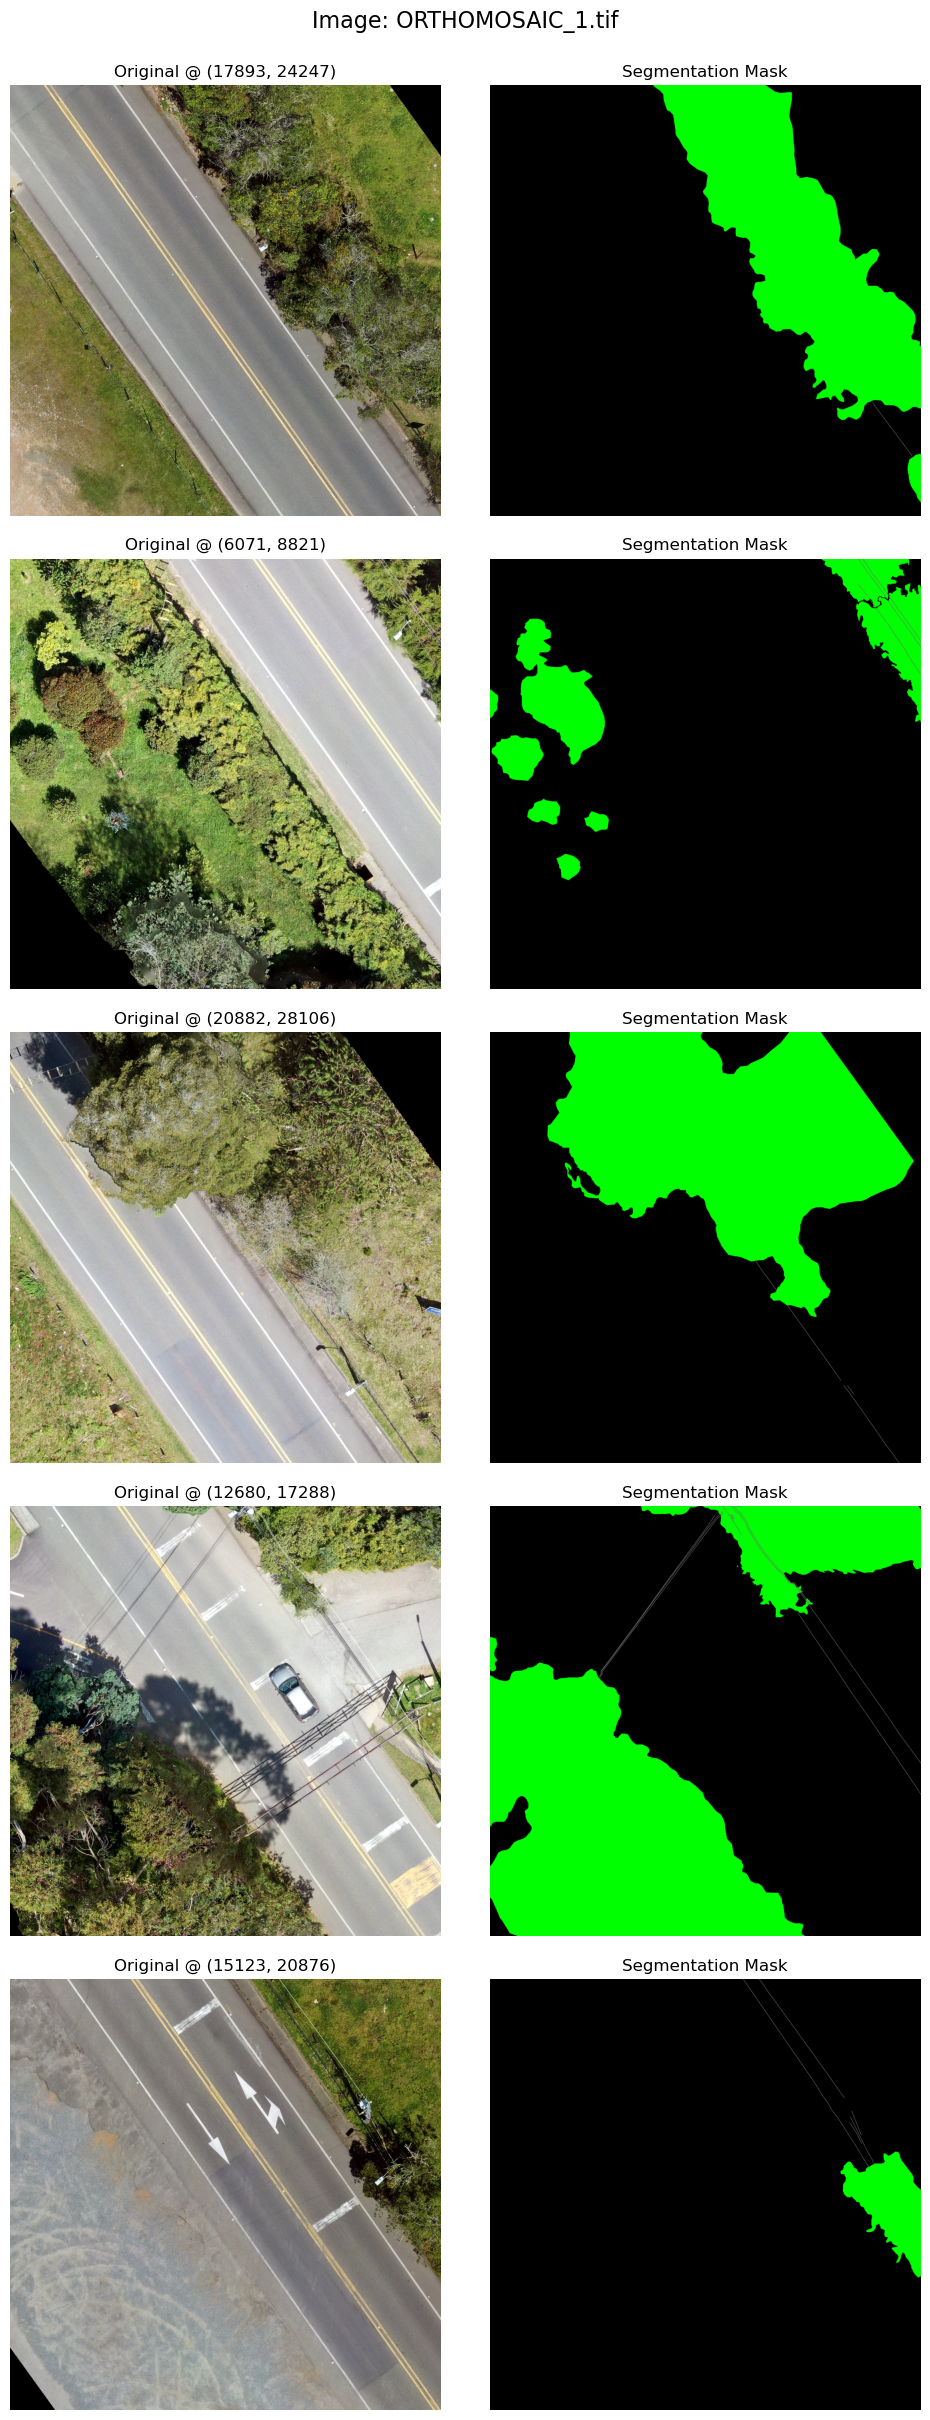

In [3]:
# --- Configuration ---
window_size = 2000
num_windows_to_find_per_image = 5
max_attempts_per_image = 1000
black_pixel_threshold = 0.10
num_files_to_process = 1 # Set to None to process all files

# --- Plotting Configuration ---
single_plot_width_inches, single_plot_height_inches = 5, 5
plot_cols = 2

ortho_dir = '../vepl_dataset/ORTHOMOSAIC'
mask_dir = '../vepl_dataset/MASK'

# --- Main Logic ---
try:
    ortho_files = sorted([f for f in os.listdir(ortho_dir) if f.endswith('.tif')])
    if not ortho_files:
        raise FileNotFoundError(f"No .tif files found in {ortho_dir}")

    # --- Limit the number of files to process ---
    if num_files_to_process is not None:
        print(f"Processing the first {num_files_to_process} files found.")
        ortho_files = ortho_files[:num_files_to_process]
    # -------------------------------------------

    for ortho_name in ortho_files:
        mask_name = ortho_name.replace("ORTHOMOSAIC_", "MASK_")
        ortho_path = os.path.join(ortho_dir, ortho_name)
        mask_path = os.path.join(mask_dir, mask_name)

        if not os.path.exists(mask_path):
            print(f"Skipping '{ortho_name}': mask not found.")
            continue

        found_windows = []
        attempts = 0

        with rasterio.open(ortho_path) as src_ortho, rasterio.open(mask_path) as src_mask:
            
            ortho_width, ortho_height = src_ortho.width, src_ortho.height
            mask_width, mask_height = src_mask.width, src_mask.height
            
            print(f"\nProcessing '{ortho_name}' ({ortho_width}x{ortho_height})")
            print(f"with mask '{mask_name}' ({mask_width}x{mask_height})")

            # We'll base our random window selection on the larger orthomosaic
            while len(found_windows) < num_windows_to_find_per_image and attempts < max_attempts_per_image:
                attempts += 1
                
                rand_col = random.randint(0, ortho_width - window_size)
                rand_row = random.randint(0, ortho_height - window_size)
                window = Window(rand_col, rand_row, window_size, window_size)

                # Read the ortho subset first. This defines our target shape.
                ortho_subset = src_ortho.read(window=window)
                
                is_black_pixel = np.all(ortho_subset == 0, axis=0)
                black_pixel_ratio = np.sum(is_black_pixel) / (window_size * window_size)

                if black_pixel_ratio < black_pixel_threshold:
                    
                    # Read the corresponding window from the mask.
                    # Rasterio handles reading up to the smaller boundary automatically.
                    mask_subset_rgb = src_mask.read(window=window, masked=True)

                    # Now, ensure the mask subset has the exact same shape as the ortho subset.
                    # This handles cases where the window is on the right or bottom edge.
                    if mask_subset_rgb.shape != ortho_subset.shape:
                        # Calculate how much padding is needed for height (axis 1) and width (axis 2)
                        pad_height = ortho_subset.shape[1] - mask_subset_rgb.shape[1]
                        pad_width = ortho_subset.shape[2] - mask_subset_rgb.shape[2]
                        
                        # Define the padding structure. We pad axis 1 and 2, but not axis 0 (the color bands).
                        # We add padding only to the end (bottom/right).
                        padding = ((0, 0), (0, pad_height), (0, pad_width))
                        
                        # Pad the mask with black pixels (0) to match the ortho shape
                        mask_subset_rgb = np.pad(mask_subset_rgb, padding, mode='constant', constant_values=0)
                        print(f"  Note: Padded mask window to match ortho window shape.")

                    # print(f"  Found valid window @ ({rand_col}, {rand_row}).")
                    found_windows.append({
                        'ortho_data': ortho_subset,
                        'mask_data': mask_subset_rgb,
                        'col': rand_col, 'row': rand_row
                    })

            if found_windows:
                plot_rows = len(found_windows)
                fig, axes = plt.subplots(plot_rows, plot_cols, figsize=(plot_cols * single_plot_width_inches, plot_rows * single_plot_height_inches))
                fig.suptitle(f"Image: {ortho_name}", fontsize=16)
                if plot_rows == 1: axes = np.array([axes])

                for i, win_info in enumerate(found_windows):
                    ax_ortho = axes[i, 0]
                    ax_mask = axes[i, 1]
                    
                    ortho_for_display = np.moveaxis(win_info['ortho_data'], 0, -1)
                    ax_ortho.imshow(ortho_for_display)
                    ax_ortho.set_title(f"Original @ ({win_info['col']}, {win_info['row']})")
                    ax_ortho.axis('off')

                    mask_for_display = np.moveaxis(win_info['mask_data'], 0, -1)
                    ax_mask.imshow(mask_for_display)
                    ax_mask.set_title("Segmentation Mask")
                    ax_mask.axis('off')
                               
                fig.subplots_adjust(
                    left=0.02,      # Margin on the left
                    right=0.98,     # Margin on the right
                    bottom=0.02,    # Margin on the bottom
                    top=0.95,       # Margin on the top to make space for the suptitle
                    wspace=0.0,    # Horizontal space between columns
                    hspace=0.1     # Vertical space between rows
                )
                
                plt.show()

except Exception as e:
    print(f"An unexpected error occurred: {e}")